# Customer Churn Analysis & Prediction

## Project Overview
This project analyzes customer churn in the telecommunications industry using data analytics, exploratory data analysis (EDA), and machine learning. The goal is to understand customer behavior, identify patterns associated with customer attrition, and predict customers who may be at risk of leaving the company.

## Objectives
- Load, inspect, and clean the IBM Telco Customer Churn dataset.
- Perform exploratory data analysis to discover churn patterns.
- Analyze customer demographics, contract types, services, tenure, and billing information.
- Prepare numerical and categorical features for machine learning.
- Train and evaluate Logistic Regression and Random Forest classification models.
- Compare model performance using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Export cleaned data, churn predictions, model comparison results, and feature importance for Power BI reporting.

## Tools & Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Jupyter Notebook
- Power BI

## Dataset
The IBM Telco Customer Churn dataset contains 7,043 customer records, including customer information, subscribed services, account details, billing information, tenure, and churn status.

## Expected Outcome
The project aims to identify customer segments associated with higher churn, evaluate machine-learning models for churn prediction, and generate insights that can support customer-retention strategies.

**Note:** Model predictions are estimates, not guarantees. Model performance and business conclusions should be interpreted using the evaluation results.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("C:/Users/rajan/OneDrive/Desktop/Customer_Churn_Analysis/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [6]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 7043
Number of columns: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16 

In [11]:
# Check actual missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check blank or whitespace-only values
print("\nBlank values in each column:")
print(
    df.select_dtypes(include="object")
      .apply(lambda col: col.str.strip().eq("").sum())
)

Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank values in each column:
customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64


In [12]:
# Convert blank strings into missing values
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

# Convert the column to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges data type: float64
Missing TotalCharges: 11


In [13]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

Duplicate customer IDs: 0
Duplicate rows: 0


In [14]:
df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [16]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


customerID:
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

In [17]:
from pathlib import Path

output_path = Path("../outputs")
output_path.mkdir(parents=True, exist_ok=True)

df.to_csv(output_path / "telco_churn_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("\nData types:")
print(df.dtypes)

Final dataset shape: (7043, 21)
Missing values: 0
Duplicate customer IDs: 0

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [19]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
total_customers = df["customerID"].nunique()

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

total_monthly_revenue = df["MonthlyCharges"].sum()

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")
print(f"Total Monthly Charges: ${total_monthly_revenue:,.2f}")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%
Retention Rate: 73.46%
Total Monthly Charges: $456,116.60


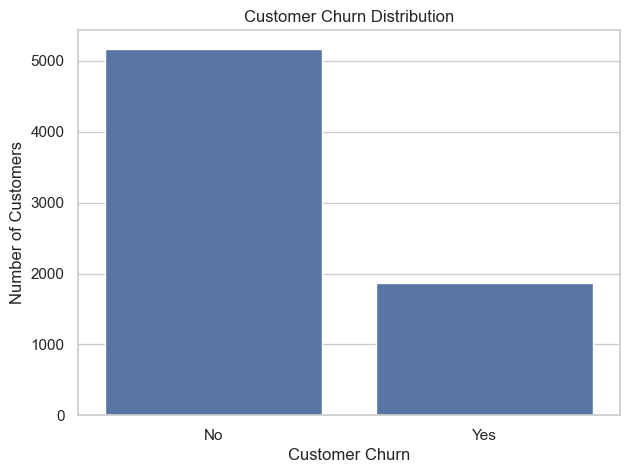

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [22]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


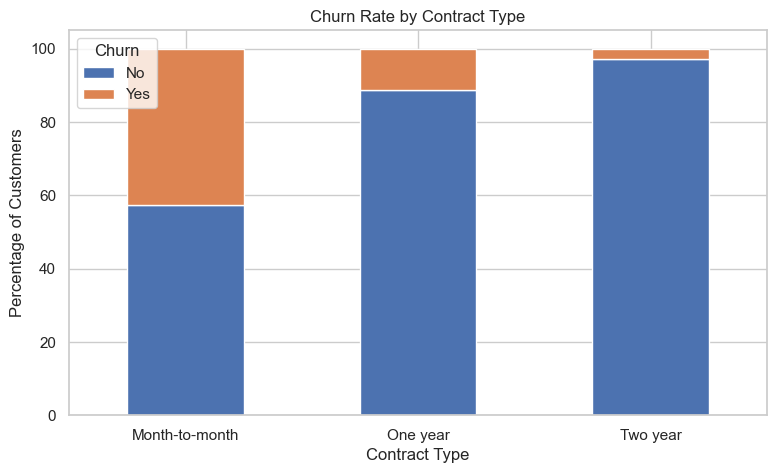

In [23]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.show()

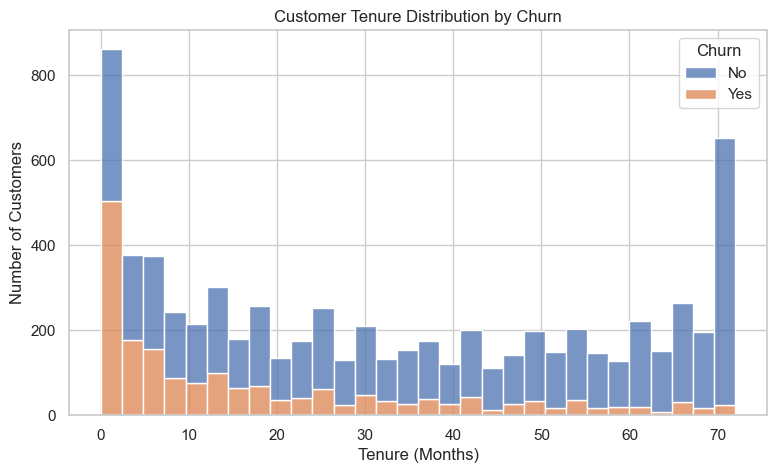

In [24]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

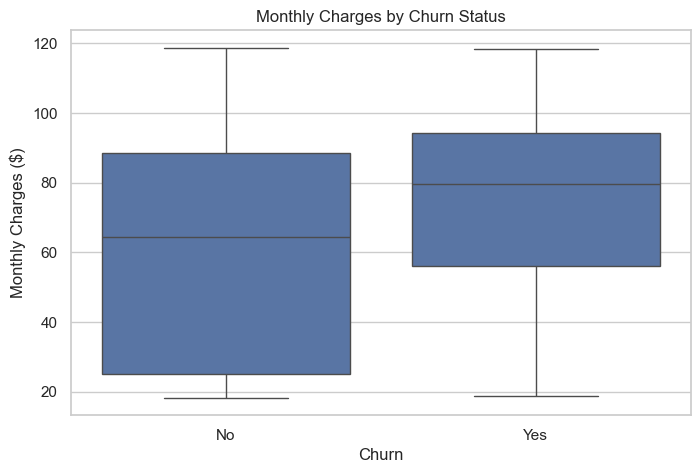

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges ($)")

plt.show()

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


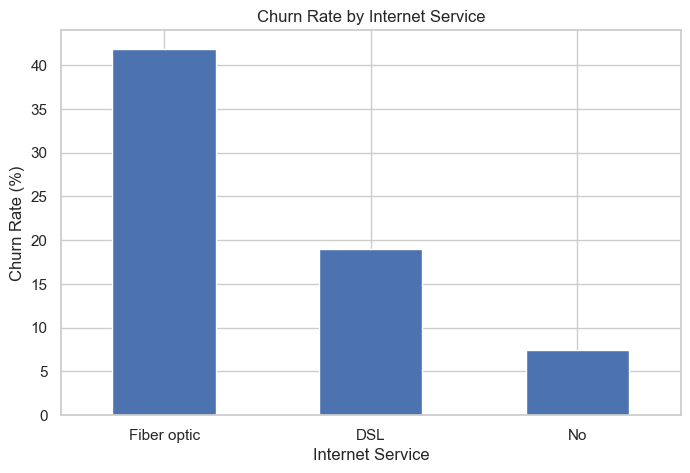

In [26]:
churn_by_internet = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

print(churn_by_internet.round(2))

churn_by_internet.plot(kind="bar", figsize=(8, 5))
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


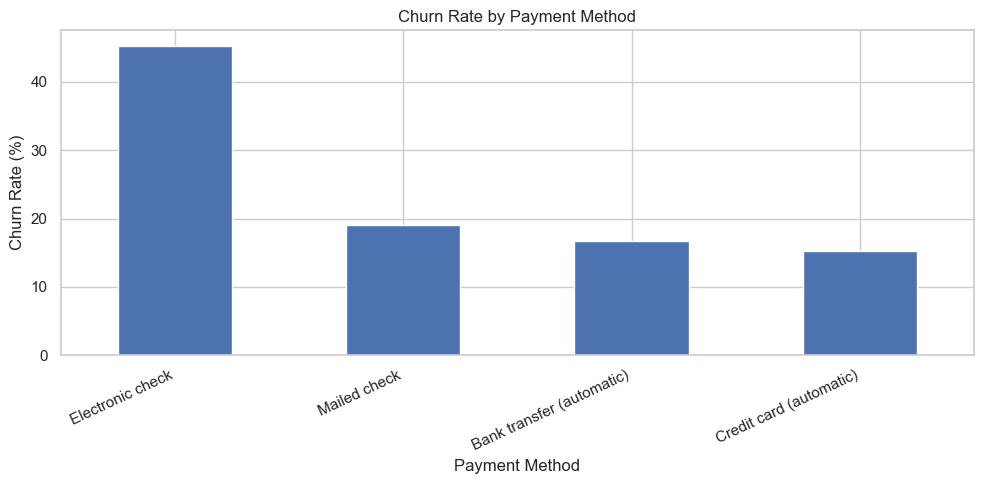

In [27]:
churn_by_payment = (
    df.groupby("PaymentMethod")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

print(churn_by_payment.round(2))

churn_by_payment.plot(kind="bar", figsize=(10, 5))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

PaperlessBilling
No     16.33
Yes    33.57
Name: Churn, dtype: float64


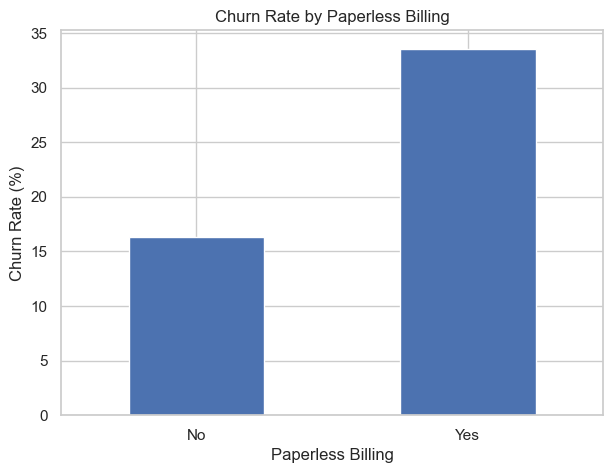

In [28]:
churn_by_billing = (
    df.groupby("PaperlessBilling")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(churn_by_billing.round(2))

churn_by_billing.plot(kind="bar", figsize=(7, 5))
plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

SeniorCitizenLabel
Non-Senior Citizen    23.61
Senior Citizen        41.68
Name: Churn, dtype: float64


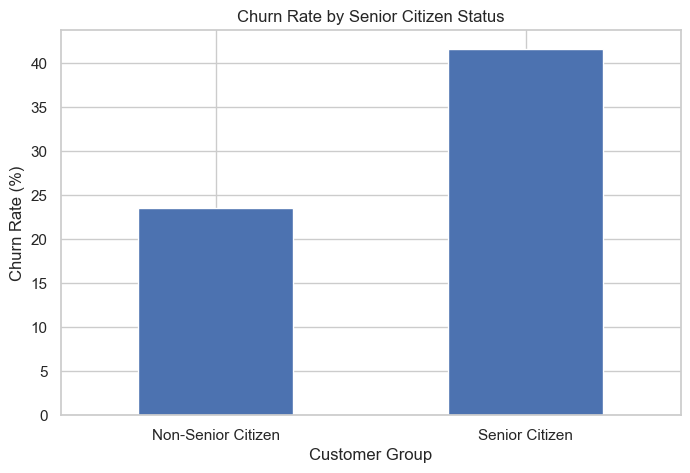

In [29]:
df["SeniorCitizenLabel"] = df["SeniorCitizen"].map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

churn_by_age_group = (
    df.groupby("SeniorCitizenLabel")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(churn_by_age_group.round(2))

churn_by_age_group.plot(kind="bar", figsize=(8, 5))
plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()


Churn Rate by Partner:
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64


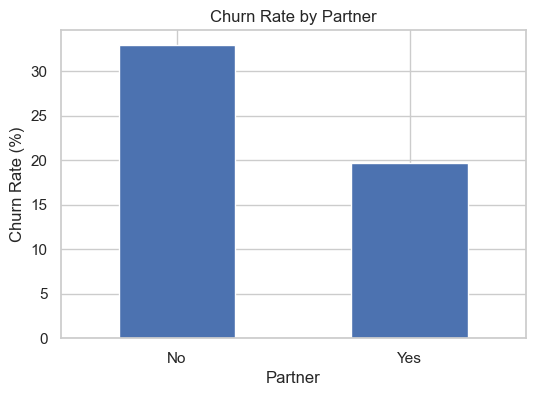


Churn Rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


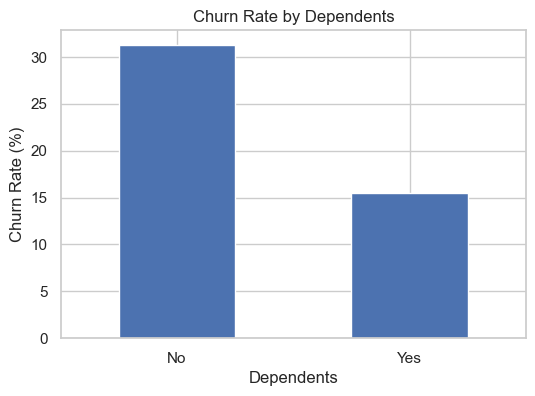

In [30]:
features = ["Partner", "Dependents"]

for feature in features:
    churn_rate = (
        df.groupby(feature)["Churn"]
          .apply(lambda x: (x == "Yes").mean() * 100)
    )

    print(f"\nChurn Rate by {feature}:")
    print(churn_rate.round(2))

    churn_rate.plot(kind="bar", figsize=(6, 4))
    plt.title(f"Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=0)
    plt.show()

Churn Rate by Tenure Group:
TenureGroup
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-60 Months    14.42
61-72 Months     6.61
Name: Churn, dtype: float64


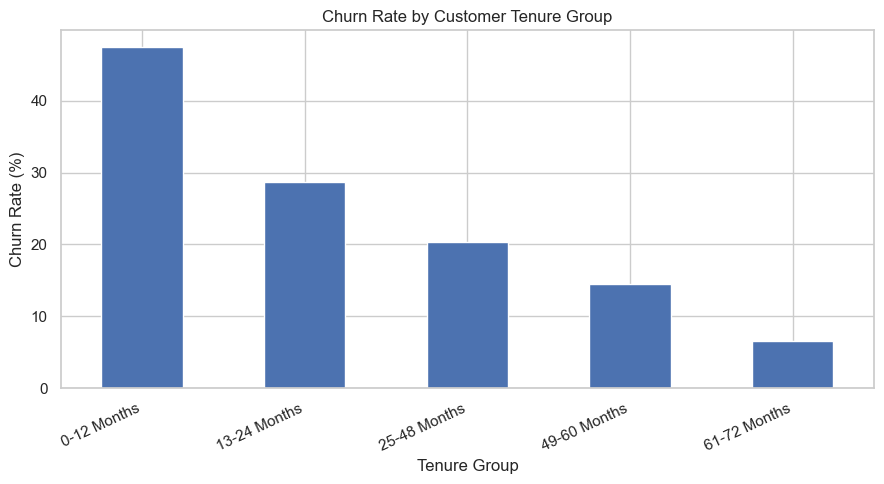

In [31]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)

tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn Rate by Tenure Group:")
print(tenure_churn.round(2))

tenure_churn.plot(kind="bar", figsize=(9, 5))
plt.title("Churn Rate by Customer Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [32]:
analysis_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizenLabel",
    "Partner",
    "Dependents",
    "TenureGroup"
]

insights = []

for feature in analysis_features:
    summary = (
        df.groupby(feature, observed=False)["Churn"]
          .agg(
              Total_Customers="count",
              Churned_Customers=lambda x: (x == "Yes").sum()
          )
          .reset_index()
    )

    summary["Churn_Rate_Percent"] = (
        summary["Churned_Customers"]
        / summary["Total_Customers"] * 100
    )

    summary.insert(0, "Feature", feature)
    summary = summary.rename(columns={feature: "Category"})
    insights.append(summary)

churn_insights = pd.concat(insights, ignore_index=True)

churn_insights["Churn_Rate_Percent"] = (
    churn_insights["Churn_Rate_Percent"].round(2)
)

churn_insights.sort_values(
    "Churn_Rate_Percent",
    ascending=False
).head(15)

,Feature,Category,Total_Customers,Churned_Customers,Churn_Rate_Percent
18,TenureGroup,0-12 Months,2186,1037,47.44
8,PaymentMethod,Electronic check,2365,1071,45.29
0,Contract,Month-to-month,3875,1655,42.71
4,InternetService,Fiber optic,3096,1297,41.89
13,SeniorCitizenLabel,Senior Citizen,1142,476,41.68
11,PaperlessBilling,Yes,4171,1400,33.57
14,Partner,No,3641,1200,32.96
16,Dependents,No,4933,1543,31.28
19,TenureGroup,13-24 Months,1024,294,28.71
12,SeniorCitizenLabel,Non-Senior Citizen,5901,1393,23.61


In [33]:
churn_insights.to_csv(
    "../outputs/churn_business_insights.csv",
    index=False
)

print("Business insights saved successfully!")

Business insights saved successfully!


In [34]:
import sqlite3
import pandas as pd

# Create a local SQL database
conn = sqlite3.connect("C:/Users/rajan/OneDrive/Desktop/Customer_Churn_Analysis/outputs/customer_churn.db")

print("Database connected successfully!")

Database connected successfully!


In [35]:
# Select customer-related columns
customer_columns = [
    "customerID",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]

# Select service-related columns
service_columns = [
    "customerID",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Create SQL tables from the cleaned DataFrame
df[customer_columns].to_sql(
    "customers", conn, if_exists="replace", index=False
)

df[service_columns].to_sql(
    "services", conn, if_exists="replace", index=False
)

print("Both SQL tables created successfully!")

Both SQL tables created successfully!


In [36]:
query1 = """
SELECT
    Churn,
    COUNT(*) AS customer_count,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*) FROM customers),
        2
    ) AS percentage
FROM customers
GROUP BY Churn;
"""

pd.read_sql_query(query1, conn)

,Churn,customer_count,percentage
0,No,5174,73.46
1,Yes,1869,26.54


In [37]:
query2 = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 *
        SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY Contract
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query2, conn)

,Contract,total_customers,churned_customers,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [38]:
query3 = """
SELECT
    c.customerID,
    c.Contract,
    c.MonthlyCharges,
    c.Churn,
    s.InternetService,
    s.TechSupport
FROM customers AS c
INNER JOIN services AS s
    ON c.customerID = s.customerID
LIMIT 10;
"""

pd.read_sql_query(query3, conn)

,customerID,Contract,MonthlyCharges,Churn,InternetService,TechSupport
0,7590-VHVEG,Month-to-month,29.85,No,DSL,No
1,5575-GNVDE,One year,56.95,No,DSL,No
2,3668-QPYBK,Month-to-month,53.85,Yes,DSL,No
3,7795-CFOCW,One year,42.30,No,DSL,Yes
4,9237-HQITU,Month-to-month,70.70,Yes,Fiber optic,No
5,9305-CDSKC,Month-to-month,99.65,Yes,Fiber optic,No
6,1452-KIOVK,Month-to-month,89.10,No,Fiber optic,No
7,6713-OKOMC,Month-to-month,29.75,No,DSL,No
8,7892-POOKP,Month-to-month,104.80,Yes,Fiber optic,Yes
9,6388-TABGU,One year,56.15,No,DSL,No


In [39]:
query4 = """
WITH contract_summary AS (
    SELECT
        Contract,
        COUNT(*) AS total_customers,
        SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
            AS churned_customers
    FROM customers
    GROUP BY Contract
)
SELECT
    Contract,
    total_customers,
    churned_customers,
    ROUND(
        100.0 * churned_customers / total_customers,
        2
    ) AS churn_rate
FROM contract_summary
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query4, conn)

,Contract,total_customers,churned_customers,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [40]:
query5 = """
SELECT
    customerID,
    Contract,
    MonthlyCharges,
    Churn,
    RANK() OVER (
        PARTITION BY Contract
        ORDER BY MonthlyCharges DESC
    ) AS charge_rank
FROM customers
ORDER BY Contract, charge_rank
LIMIT 20;
"""

pd.read_sql_query(query5, conn)

,customerID,Contract,MonthlyCharges,Churn,charge_rank
0,2302-ANTDP,Month-to-month,117.45,Yes,1
1,8016-NCFVO,Month-to-month,116.50,No,2
2,9659-QEQSY,Month-to-month,115.65,No,3
3,4361-BKAXE,Month-to-month,114.50,Yes,4
4,6710-HSJRD,Month-to-month,114.10,No,5
5,9158-VCTQB,Month-to-month,113.60,Yes,6
6,7279-BUYWN,Month-to-month,113.20,Yes,7
7,0771-WLCLA,Month-to-month,112.95,No,8
8,1583-IHQZE,Month-to-month,112.95,Yes,8
9,9481-IEBZY,Month-to-month,112.90,No,10


In [41]:
query6 = """
SELECT
    s.InternetService,
    s.TechSupport,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN c.Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 *
        SUM(CASE WHEN c.Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*),
        2
    ) AS churn_rate
FROM customers AS c
INNER JOIN services AS s
    ON c.customerID = s.customerID
GROUP BY
    s.InternetService,
    s.TechSupport
HAVING COUNT(*) >= 50
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query6, conn)

,InternetService,TechSupport,total_customers,churned_customers,churn_rate
0,Fiber optic,No,2230,1101,49.37
1,DSL,No,1243,345,27.76
2,Fiber optic,Yes,866,196,22.63
3,DSL,Yes,1178,114,9.68
4,No,No internet service,1526,113,7.40


In [42]:
# Export the joined customer and service data for Power BI
joined_df = pd.read_sql_query(
    """
    SELECT c.*, s.InternetService, s.TechSupport,
           s.OnlineSecurity, s.OnlineBackup,
           s.DeviceProtection, s.StreamingTV,
           s.StreamingMovies, s.PhoneService,
           s.MultipleLines
    FROM customers c
    INNER JOIN services s
        ON c.customerID = s.customerID
    """,
    conn
)

joined_df.to_csv(
    "../outputs/customer_churn_sql_export.csv",
    index=False
)

print("SQL analysis export saved successfully!")

SQL analysis export saved successfully!


In [43]:
conn.close()

In [44]:
# Remove columns created only for EDA
df_model = df.drop(
    columns=["SeniorCitizenLabel", "TenureGroup"],
    errors="ignore"
).copy()

# Remove customer ID because it is an identifier, not a useful predictor
X = df_model.drop(columns=["customerID", "Churn"])

# Target variable
y = df_model["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5634
Testing records: 1409


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing setup completed!")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Preprocessing setup completed!


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Churned"],
        zero_division=0
    ))

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)


Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Random Forest
              precision    recall  f1-score   support

      Stayed       0.83      0.90      0.86      1035
     Churned       0.64      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Random Forest,0.793,0.642,0.503,0.564,0.833


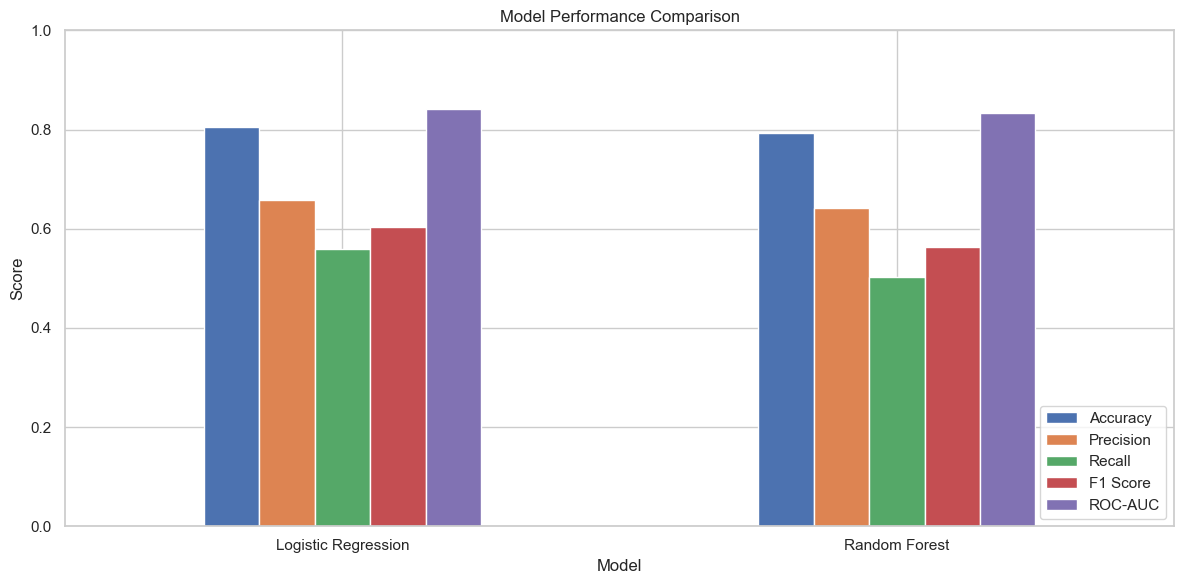

In [49]:
results_df[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [50]:
rf_pipeline = trained_models["Random Forest"]

feature_names = (
    rf_pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

importances = rf_pipeline.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
1,numeric__tenure,0.144451
3,numeric__TotalCharges,0.140150
2,numeric__MonthlyCharges,0.110407
36,categorical__Contract_Month-to-month,0.071762
18,categorical__OnlineSecurity_No,0.044592
16,categorical__InternetService_Fiber optic,0.038462
27,categorical__TechSupport_No,0.036207
43,categorical__PaymentMethod_Electronic check,0.035931
38,categorical__Contract_Two year,0.021937
21,categorical__OnlineBackup_No,0.019379


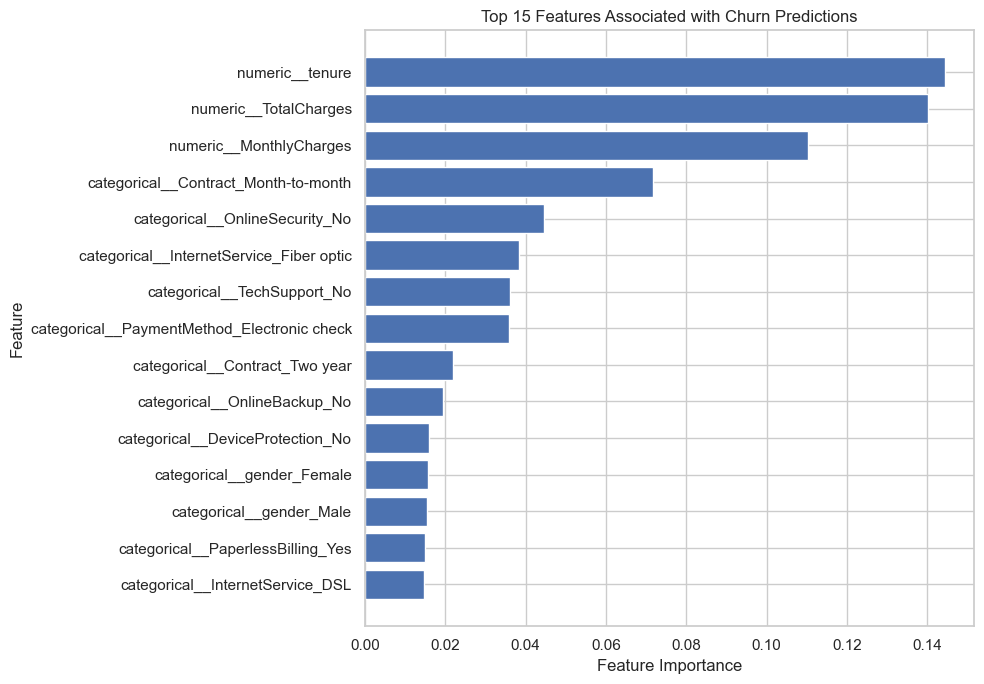

In [51]:
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features Associated with Churn Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [52]:
from pathlib import Path

output_path = Path("../outputs")
output_path.mkdir(parents=True, exist_ok=True)

results_df.to_csv(output_path / "model_comparison.csv")
feature_importance.to_csv(
    output_path / "feature_importance.csv",
    index=False
)

print("Model comparison and feature importance saved!")

Model comparison and feature importance saved!


In [53]:
print(results_df.round(3))

                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                              
Logistic Regression     0.806      0.657   0.559     0.604    0.842
Random Forest           0.793      0.642   0.503     0.564    0.833


In [54]:
import os

print("Output files:")
print(os.listdir("outputs"))

Output files:
['customer_churn.db']


In [55]:
from pathlib import Path

# Create output folder if it doesn't exist
output_path = Path("outputs")
output_path.mkdir(parents=True, exist_ok=True)

# Save model comparison
results_df.to_csv(
    output_path / "model_comparison.csv",
    index=True
)

# Save feature importance
feature_importance.to_csv(
    output_path / "feature_importance.csv",
    index=False
)

# Export cleaned customer data for Power BI
df.to_csv(
    output_path / "telco_churn_cleaned.csv",
    index=False
)

# Generate predictions using Logistic Regression
best_model = trained_models["Logistic Regression"]

predictions = best_model.predict(X_test)
churn_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create customer-level prediction report
prediction_report = df.loc[
    X_test.index,
    ["customerID", "Contract", "tenure", "MonthlyCharges", "Churn"]
].copy()

prediction_report["Actual_Churn"] = y_test
prediction_report["Predicted_Churn"] = predictions
prediction_report["Churn_Probability"] = churn_probabilities

prediction_report.to_csv(
    output_path / "customer_churn_predictions.csv",
    index=False
)

# Verify saved files
print("Files saved successfully:")
for file in sorted(output_path.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size:,} bytes")

Files saved successfully:
customer_churn.db — 1,187,840 bytes
customer_churn_predictions.csv — 84,133 bytes
feature_importance.csv — 2,515 bytes
model_comparison.csv — 276 bytes
telco_churn_cleaned.csv — 1,197,608 bytes


In [56]:
from pathlib import Path

readme_content = """# Customer Churn Analysis & Prediction

## Project Overview

Customer Churn Analysis & Prediction uses Python, SQL,
machine learning, and Power BI to analyze customer churn.

## Tools and Technologies

- Python
- Pandas and NumPy
- Scikit-learn
- SQL / SQLite
- Jupyter Notebook
- Power BI

## Machine-Learning Results

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 80.6% | 79.3% |
| Precision | 65.7% | 64.2% |
| Recall | 55.9% | 50.3% |
| F1-score | 60.4% | 56.4% |
| ROC-AUC | 0.842 | 0.833 |

## Conclusion

This project combines data analysis, SQL validation,
machine learning, and interactive Power BI reporting.
"""

Path("README.md").write_text(readme_content, encoding="utf-8")

print("README.md created at:", Path("README.md").resolve())

README.md created at: C:\Users\rajan\OneDrive\Desktop\Customer_Churn_Analysis\README.md
